<a href="https://colab.research.google.com/github/Ninezik/if5141dmproject/blob/main/datamining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
lokasi_publication_distribution='/content/drive/MyDrive/datasets_itb/distributionofpublicationtype.csv'

In [5]:
df_publication_distribution=pd.read_csv(lokasi_publication_distribution,delimiter=';')

In [6]:
df_publication_distribution.info()
df_publication_distribution

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   type           7 non-null      object 
 1   #Publications  7 non-null      int64  
 2   Unnamed: 2     0 non-null      float64
dtypes: float64(1), int64(1), object(1)
memory usage: 300.0+ bytes


,type,#Publications,Unnamed: 2
0,Book and Theses,177604,NaN
1,Conference and Workshop Papers,3996214,NaN
2,Editorship,68343,NaN
3,Informal Publications,1080519,NaN
4,Journal Articles,3472525,NaN
5,Parts in Books or Collections,43899,NaN
6,Reference Works,27365,NaN


In [7]:
df_publication_distribution=df_publication_distribution[['type','#Publications']]

Text(0.5, 1.0, 'Jumlah Publikasi per tipe publikasi seluruh data')

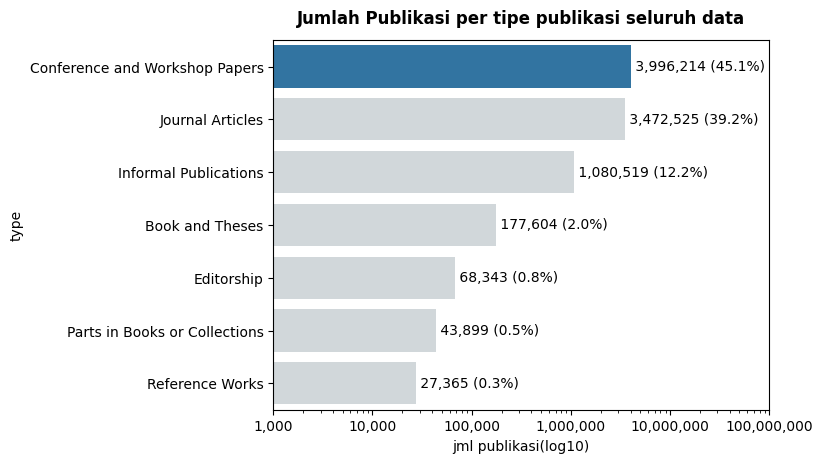

In [8]:
import seaborn as sns
import matplotlib.ticker as ticker
df_sorted = df_publication_distribution.sort_values(by='#Publications', ascending=False)
colors = [
    "#1f77b4" if t == "Conference and Workshop Papers" else "#cfd8dc"
    for t in df_sorted["type"]
]
ax = sns.barplot(
    df_sorted,
    x="#Publications",
    y="type",
    hue="type",
    palette=colors,
    legend=False
)
ax.set_xscale("log")
ax.set_xlim(1000, 100000000)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):,}"))
total = df_sorted['#Publications'].sum()
labels = [f" {val:,.0f} ({val/total*100:.1f}%)" for val in df_sorted['#Publications']]

for container, label in zip(ax.containers, labels):
    ax.bar_label(container, labels=[label], fontsize=10)

ax.set_xlabel("jml publikasi(log10)");
ax.set_title("Jumlah Publikasi per tipe publikasi seluruh data", fontsize=12, fontweight="bold", pad=12)

In [9]:
# lokasi='/content/drive/MyDrive/datasets_itb/dblp_2015_2025.parquet'
# df=pd.read_parquet(lokasi)

In [10]:
# df.info()
# df.head()

In [11]:
# # uppercase
# df['title']=df['title'].str.upper()

In [12]:
# import seaborn as sns

# # 1. Urutkan tahun & hitung persentase perubahan dari tahun sebelumnya
# df_year = df.groupby(['year']).size().reset_index(name='jumlah').sort_values('year')
# df_year['pct_change'] = df_year['jumlah'].pct_change() * 100

# # 2. Buat lineplot & judul
# ax = sns.lineplot(data=df_year, x="year", y="jumlah")
# ax.set_title("""Trendline Jumlah publikasi konferensi dan workshop
# (inproceedings) 2015-2025""", fontsize=12, fontweight="bold", pad=12)

# # 3. Ambil data baris terakhir (jumlah & persentase perubahannya)
# last_row = df_year.iloc[-1]
# last_x = last_row['year']
# last_y = last_row['jumlah']
# last_pct = last_row['pct_change']

# # 4. Tandai titik terakhir & tampilkan jumlah + persentase perubahan
# ax.scatter(last_x, last_y, color='#1f77b4', zorder=5)
# ax.annotate(
#     f"{last_y:,.0f} ({last_pct:+.2f}%)",
#     xy=(last_x, last_y),
#     xytext=(6, 0),
#     textcoords="offset points",
#     va="center",
#     fontsize=10,
#     fontweight="bold"
# )

# # 5. Perlebar batas kanan agar teks panjang tidak terpotong
# x_min, x_max = ax.get_xlim()
# ax.set_xlim(x_min, x_max + (x_max - x_min) * 0.15);

In [13]:
# len(df)

In [14]:
# df[df['title'].duplicated()].iloc[106]['title']

In [15]:
# df.drop_duplicates(subset='title',inplace=True)

In [16]:
# df

cek data raw jenis 2

In [17]:
lokasi_raw2='/content/drive/MyDrive/datasets_itb/dblp_2015_2025_raw.parquet'

In [18]:
df2=pd.read_parquet(lokasi_raw2)

In [19]:
df2.info()
df2.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2004019 entries, 0 to 2004018
Data columns (total 10 columns):
 #   Column    Dtype 
---  ------    ----- 
 0   key       object
 1   mdate     object
 2   authors   object
 3   title     object
 4   pages     object
 5   year      int64 
 6   venue     object
 7   doi       object
 8   crossref  object
 9   url       object
dtypes: int64(1), object(9)
memory usage: 152.9+ MB


,key,mdate,authors,title,pages,year,venue,doi,crossref,url
0,books/sp/15/KimLLRJPK15,2026-06-03,"[Kwang-Ho Kim, Donghyun Lee 0001, Minkyu Lim, ...",Performance Analysis of FFNN-Based Language Mo...,253-256,2015,IWSDS,https://doi.org/10.1007/978-3-319-19291-8_25,books/sp/2015LKJK,db/books/collections/LKJK2015.html#KimLLRJPK15
1,books/sp/15/ManuvinakurikeD15,2021-04-29,"[Ramesh R. Manuvinakurike, David DeVault]",Pair Me Up: A Web Framework for Crowd-Sourced ...,189-201,2015,IWSDS,https://doi.org/10.1007/978-3-319-19291-8_18,books/sp/2015LKJK,db/books/collections/LKJK2015.html#Manuvinakur...
2,books/sp/15/YoshinoK15,2021-04-29,"[Koichiro Yoshino, Tatsuya Kawahara]",News Navigation System Based on Proactive Dial...,15-25,2015,IWSDS,https://doi.org/10.1007/978-3-319-19291-8_2,books/sp/2015LKJK,db/books/collections/LKJK2015.html#YoshinoK15
3,books/sp/15/KwonLRHCKJOLKCPL15,2021-10-14,"[Oh-Woog Kwon, Ki-Young Lee, Yoon-Hyung Roh, J...",GenieTutor: A Computer-Assisted Second-Languag...,257-262,2015,IWSDS,https://doi.org/10.1007/978-3-319-19291-8_26,books/sp/2015LKJK,db/books/collections/LKJK2015.html#KwonLRHCKJO...
4,books/sp/15/HanKL15,2021-04-29,"[Sangdo Han, Yonghee Kim, Gary Geunbae Lee]",Micro-Counseling Dialog System Based on Semant...,63-72,2015,IWSDS,https://doi.org/10.1007/978-3-319-19291-8_6,books/sp/2015LKJK,db/books/collections/LKJK2015.html#HanKL15


In [20]:
len(df2)

2004019

In [21]:
len(df2[df2['authors'].str.len()==0])

2255

In [22]:
df2[['authors','title','year','venue']].isnull().sum()

,0
authors,0
title,0
year,0
venue,190


In [23]:
df2.dropna(subset='venue',inplace=True)

In [24]:
# cek deuiu
df2.isnull().sum()

,0
key,0
mdate,0
authors,0
title,0
pages,122181
year,0
venue,0
doi,6352
crossref,2471
url,0


In [25]:
# df2.fillna('0',inplace=True)

In [26]:
df2.isnull().sum()

,0
key,0
mdate,0
authors,0
title,0
pages,122181
year,0
venue,0
doi,6352
crossref,2471
url,0


In [27]:
df2=df2[df2['authors'].str.len()>0]

In [28]:
len(df2)

2001574

In [29]:
df2.isnull().sum()

,0
key,0
mdate,0
authors,0
title,0
pages,121901
year,0
venue,0
doi,6333
crossref,2470
url,0


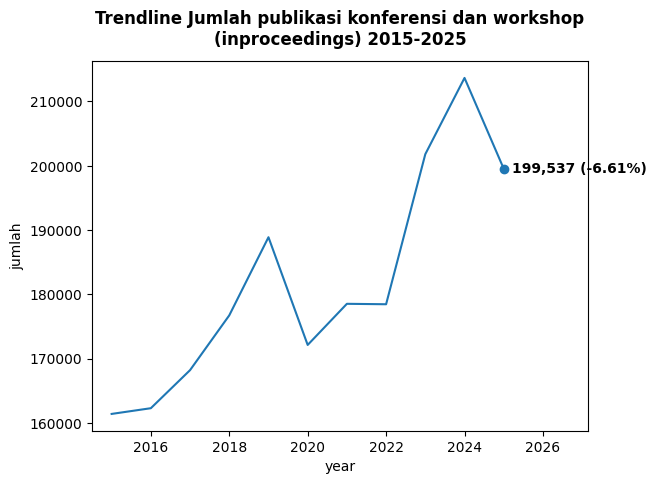

In [30]:
import seaborn as sns

# 1. Urutkan tahun & hitung persentase perubahan dari tahun sebelumnya
df_year = df2.groupby(['year']).size().reset_index(name='jumlah').sort_values('year')
df_year['pct_change'] = df_year['jumlah'].pct_change() * 100

# 2. Buat lineplot & judul
ax = sns.lineplot(data=df_year, x="year", y="jumlah")
ax.set_title("""Trendline Jumlah publikasi konferensi dan workshop
(inproceedings) 2015-2025""", fontsize=12, fontweight="bold", pad=12)

# 3. Ambil data baris terakhir (jumlah & persentase perubahannya)
last_row = df_year.iloc[-1]
last_x = last_row['year']
last_y = last_row['jumlah']
last_pct = last_row['pct_change']

# 4. Tandai titik terakhir & tampilkan jumlah + persentase perubahan
ax.scatter(last_x, last_y, color='#1f77b4', zorder=5)
ax.annotate(
    f"{last_y:,.0f} ({last_pct:+.2f}%)",
    xy=(last_x, last_y),
    xytext=(6, 0),
    textcoords="offset points",
    va="center",
    fontsize=10,
    fontweight="bold"
)

# 5. Perlebar batas kanan agar teks panjang tidak terpotong
x_min, x_max = ax.get_xlim()
ax.set_xlim(x_min, x_max + (x_max - x_min) * 0.15);

cek duplikat

In [31]:
# kombinasi dari title,author,venue, year
import numpy as np

df2["authors_tuple"] = df2["authors"].apply(
    lambda x: tuple(x) if isinstance(x, (list, np.ndarray)) else x
)
df2.duplicated(['title','authors_tuple','venue','year']).sum()

np.int64(615)

In [32]:
df2.sort_values('key', inplace=True)
df2.drop_duplicates(subset=['title', 'authors_tuple', 'venue', 'year'], keep='first', inplace=True)

In [33]:
df2.duplicated(['title','authors_tuple','venue','year']).sum()

np.int64(0)

In [34]:
df2.iloc[0]

,11
key,books/sp/15/CorbinMT15
mdate,2021-04-29
authors,"[Carina Corbin, Fabrizio Morbini, David R. Traum]"
title,Creating a Virtual Neighbor.
pages,203-208
year,2015
venue,IWSDS
doi,https://doi.org/10.1007/978-3-319-19291-8_19
crossref,books/sp/2015LKJK
url,db/books/collections/LKJK2015.html#CorbinMT15


normalisasi author

In [35]:
import re
import unicodedata
def normalize_authors(authors):
    result = []

    for name in authors:
        if isinstance(name, str):
            name = unicodedata.normalize('NFKC', name)
            name = name.lower().strip()
            name = re.sub(r'\s+', ' ', name)
            name = name.strip('.,;:')

        result.append(name)

    return result

df2['authors_normalized'] = df2['authors'].apply(normalize_authors)

In [36]:
df2

,key,mdate,authors,title,pages,year,venue,doi,crossref,url,authors_tuple,authors_normalized
11,books/sp/15/CorbinMT15,2021-04-29,"[Carina Corbin, Fabrizio Morbini, David R. Traum]",Creating a Virtual Neighbor.,203-208,2015,IWSDS,https://doi.org/10.1007/978-3-319-19291-8_19,books/sp/2015LKJK,db/books/collections/LKJK2015.html#CorbinMT15,"(Carina Corbin, Fabrizio Morbini, David R. Traum)","[carina corbin, fabrizio morbini, david r. traum]"
17,books/sp/15/DHaroKYJNBL15,2021-04-29,"[Luis Fernando D'Haro, Seokhwan Kim, Kheng Hui...",CLARA: A Multifunctional Virtual Agent for Con...,233-239,2015,IWSDS,https://doi.org/10.1007/978-3-319-19291-8_22,books/sp/2015LKJK,db/books/collections/LKJK2015.html#DHaroKYJNBL15,"(Luis Fernando D'Haro, Seokhwan Kim, Kheng Hui...","[luis fernando d'haro, seokhwan kim, kheng hui..."
12,books/sp/15/EsteveBLMDLMM15,2021-04-29,"[Yannick Estève, Mohamed Bouallegue, Carole La...",Integration of Word and Semantic Features for ...,223-231,2015,IWSDS,https://doi.org/10.1007/978-3-319-19291-8_21,books/sp/2015LKJK,db/books/collections/LKJK2015.html#EsteveBLMDL...,"(Yannick Estève, Mohamed Bouallegue, Carole La...","[yannick estève, mohamed bouallegue, carole la..."
14,books/sp/15/FerreiraMLA15,2026-03-24,"[Emmanuel Ferreira, Grégoire Milliez, Fabrice ...",Users' Belief Awareness in Reinforcement Learn...,73-86,2015,IWSDS,https://doi.org/10.1007/978-3-319-19291-8_7,books/sp/2015LKJK,db/books/collections/LKJK2015.html#FerreiraMLA15,"(Emmanuel Ferreira, Grégoire Milliez, Fabrice ...","[emmanuel ferreira, grégoire milliez, fabrice ..."
25,books/sp/15/GhigiT15,2021-04-29,"[Fabrizio Ghigi, M. Inés Torres]",Decision Making Strategies for Finite-State Bi...,209-221,2015,IWSDS,https://doi.org/10.1007/978-3-319-19291-8_20,books/sp/2015LKJK,db/books/collections/LKJK2015.html#GhigiT15,"(Fabrizio Ghigi, M. Inés Torres)","[fabrizio ghigi, m. inés torres]"
...,...,...,...,...,...,...,...,...,...,...,...,...
2001216,journals/entcs/Zaffanella18,2022-11-10,[Enea Zaffanella],On the Efficiency of Convex Polyhedra.,31-44,2017,NSAD@SAS,https://doi.org/10.1016/j.entcs.2018.03.004,conf/nsad/2017,db/journals/entcs/entcs334.html#Zaffanella18,"(Enea Zaffanella,)",[enea zaffanella]
2001230,journals/entcs/Zanasi16,2022-08-16,[Fabio Zanasi],The Algebra of Partial Equivalence Relations.,313-333,2016,MFPS,https://doi.org/10.1016/j.entcs.2016.09.046,conf/mfps/2016,db/journals/entcs/entcs325.html#Zanasi16,"(Fabio Zanasi,)",[fabio zanasi]
2001219,journals/entcs/ZhangLX19,2022-08-16,"[Wenfeng Zhang, Wenfeng Li, Xiaoquan Xu]",s2-Quasialgebraic Posets.,293-301,2019,ISDT,https://doi.org/10.1016/j.entcs.2019.07.031,conf/isdt/2019,db/journals/entcs/entcs345.html#ZhangLX19,"(Wenfeng Zhang, Wenfeng Li, Xiaoquan Xu)","[wenfeng zhang, wenfeng li, xiaoquan xu]"
2001057,journals/entcs/ZorziFMS19,2022-08-16,"[Alesom Zorzi, Celina M. H. de Figueiredo, Rap...",Even-power of Cycles With Many Vertices are Ty...,747-758,2019,LAGOS,https://doi.org/10.1016/j.entcs.2019.08.065,conf/lagos/2019,db/journals/entcs/entcs346.html#ZorziFMS19,"(Alesom Zorzi, Celina M. H. de Figueiredo, Rap...","[alesom zorzi, celina m. h. de figueiredo, rap..."


normalisasi venue(conference)

In [37]:
import unicodedata
import re

VENUE_MAPPING = {
    "nips": "neurips",
    "ieee bigdata": "ieee big data",
    "icce-tw": "icce-taiwan",
    "ismar-adjunct": "ismar adjunct",
    "fat*": "facct",
    "iccvw": "iccv workshops",
}

def normalize_venue(venue, merge_subtracks=True):
    if not isinstance(venue, str):
        return venue

    # 1. Normalisasi karakter Unicode, lowercase, dan hapus tanda kutip sisa
    venue = unicodedata.normalize('NFKC', venue).lower().strip()
    venue = venue.strip('"\'')

    # 2. Hapus nomor volume/part seperti "(1)", "(27)", "(workshops 3)"
    venue = re.sub(r'\s*\((?:workshops?\s*)?\d+\)\s*$', '', venue)

    # 3. Hapus tahun (4 digit) beserta tanda hubung/spasi yang menempel
    venue = re.sub(r'[-_\s]*\b(19|20)\d{2}\b[-_\s]*', ' ', venue)

    # 4. Rapikan spasi dan terapkan kamus sinonim dasar
    venue = re.sub(r'\s+', ' ', venue).strip()
    venue = VENUE_MAPPING.get(venue, venue)

    # 5. Jika ingin menggabungkan sub-track (workshops, findings, companion, co-located @) ke induk
    if merge_subtracks:
        # Ambil konferensi induk setelah tanda '@' terakhir (misal: "(know@lod/codes)@eswc" -> "eswc")
        if '@' in venue:
            venue = venue.rsplit('@', 1)[-1].strip()

        # Hapus keterangan track dalam kurung atau di akhir nama
        venue = re.sub(r'\s*\(.*?\)\s*$', '', venue)
        venue = re.sub(
            r'\s+(workshops?|wkshps?|companion|adjunct|findings|posters?|demos?|extended abstracts|short papers|abstracts).*$',
            '',
            venue
        )
        venue = re.sub(r'\s+', ' ', venue).strip()
        venue = VENUE_MAPPING.get(venue, venue)

    return venue

# Terapkan ke DataFrame (ubah merge_subtracks=False jika ingin memisahkan workshop)
df2['venue_normalized'] = df2['venue'].apply(lambda x: normalize_venue(x, merge_subtracks=True))

cek konsistensi tahun

In [38]:
df2[(df2['year']<2015) & (df2['year']>2025)]

,key,mdate,authors,title,pages,year,venue,doi,crossref,url,authors_tuple,authors_normalized,venue_normalized


kondisi dataset setetalh preprocessing

In [39]:
# total publikasi
len(df2)

2000959

In [40]:
# total author unik

In [41]:
# total conference unik
df2['venue'].nunique()

8903

In [42]:
df2.groupby('year')['key'].count().reset_index(name='jumlah')

,year,jumlah
0,2015,161353
1,2016,162259
2,2017,168151
3,2018,176661
4,2019,188817
5,2020,172097
6,2021,178502
7,2022,178363
8,2023,201738
9,2024,213570


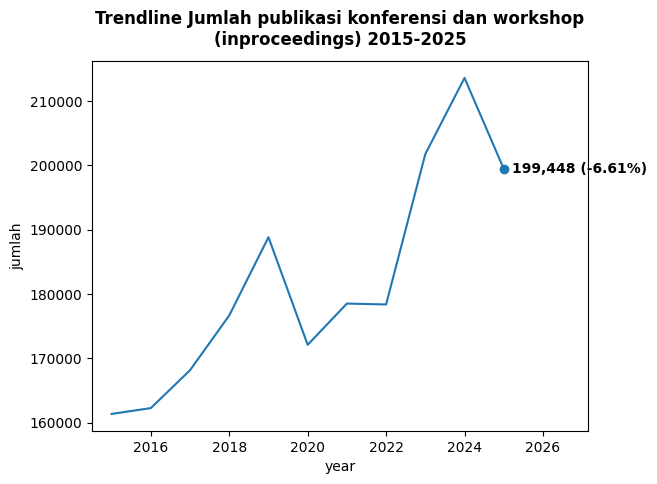

In [43]:
import seaborn as sns

# 1. Urutkan tahun & hitung persentase perubahan dari tahun sebelumnya
df_year = df2.groupby(['year'])['key'].count().reset_index(name='jumlah').sort_values('year')
df_year['pct_change'] = df_year['jumlah'].pct_change() * 100

# 2. Buat lineplot & judul
ax = sns.lineplot(data=df_year, x="year", y="jumlah")
ax.set_title("""Trendline Jumlah publikasi konferensi dan workshop
(inproceedings) 2015-2025""", fontsize=12, fontweight="bold", pad=12)

# 3. Ambil data baris terakhir (jumlah & persentase perubahannya)
last_row = df_year.iloc[-1]
last_x = last_row['year']
last_y = last_row['jumlah']
last_pct = last_row['pct_change']

# 4. Tandai titik terakhir & tampilkan jumlah + persentase perubahan
ax.scatter(last_x, last_y, color='#1f77b4', zorder=5)
ax.annotate(
    f"{last_y:,.0f} ({last_pct:+.2f}%)",
    xy=(last_x, last_y),
    xytext=(6, 0),
    textcoords="offset points",
    va="center",
    fontsize=10,
    fontweight="bold"
)

# 5. Perlebar batas kanan agar teks panjang tidak terpotong
x_min, x_max = ax.get_xlim()
ax.set_xlim(x_min, x_max + (x_max - x_min) * 0.15);

In [44]:
df2.groupby('venue_normalized')['key'].count().reset_index(name='jumlah').sort_values(by='jumlah',ascending=False)

,venue_normalized,jumlah
3241,neurips,25523
994,cvpr,22776
1868,icassp,21606
1706,hci,19913
2372,igarss,19687
...,...,...
2966,machine learning for scientific imaging,2
4056,supercompcloud,2
3056,middleware tutorials,2
3261,nip,1


Task 2 — Conference Popularity Analysis

In [45]:
# 1. Identifikasi 10 konferensi dengan jumlah publikasi terbanyak.
top10_ppc=df2.groupby('venue_normalized')['key'].count().reset_index(name='jumlah publikasi').sort_values(by='jumlah publikasi',ascending=False).iloc[:10]


In [46]:
# 2. Identifikasi 10 konferensi dengan jumlah author unik terbanyak.
top10_apc=df2[['venue_normalized','authors_normalized']].explode('authors_normalized').groupby('venue_normalized')['authors_normalized'].nunique().reset_index(name='jumlah authors').sort_values(by='jumlah authors',ascending=False).iloc[:10]
apc=df2[['venue_normalized','authors_normalized']].explode('authors_normalized').groupby('venue_normalized')['authors_normalized'].nunique().reset_index(name='jumlah authors').sort_values(by='jumlah authors',ascending=False)

In [47]:
# 3. Analisis tren jumlah publikasi konferensi berdasarkan tahun selama periode 2015–2025.
df2.groupby('year')['key'].count().reset_index(name='jumlah publikasi').sort_values(by='year')

,year,jumlah publikasi
0,2015,161353
1,2016,162259
2,2017,168151
3,2018,176661
4,2019,188817
5,2020,172097
6,2021,178502
7,2022,178363
8,2023,201738
9,2024,213570


In [48]:
# 4. Bandingkan hasil ranking berdasarkan jumlah publikasi dan jumlah author unik.
df_hasil=pd.merge(top10_ppc,apc,how='left')

In [49]:
df_hasil

,venue_normalized,jumlah publikasi,jumlah authors
0,neurips,25523,57823
1,cvpr,22776,47638
2,icassp,21606,42036
3,hci,19913,37850
4,igarss,19687,35213
5,aaai,19266,46316
6,emnlp,15528,35553
7,chi,14912,29958
8,embc,14677,39312
9,acl,14633,33514


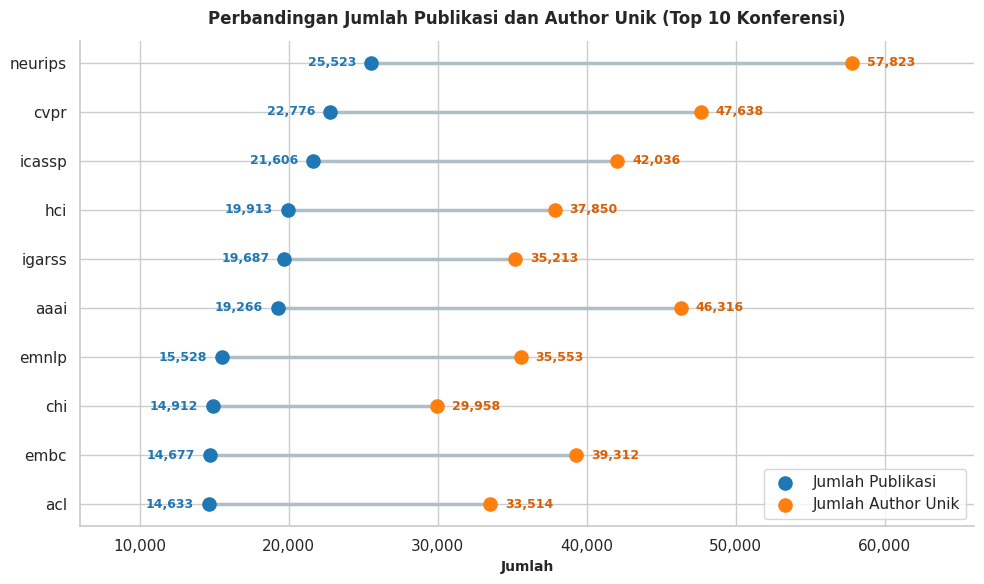

In [50]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
df_hasil.sort_values(by='jumlah publikasi',inplace=True)

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))


ax.hlines(
    y=df_hasil["venue_normalized"],
    xmin=df_hasil["jumlah publikasi"],
    xmax=df_hasil["jumlah authors"],
    color="#b0bec5",
    linewidth=2.5,
    zorder=2
)


ax.scatter(
    df_hasil["jumlah publikasi"],
    df_hasil["venue_normalized"],
    color="#1f77b4",
    s=90,
    label="Jumlah Publikasi",
    zorder=3
)
ax.scatter(
    df_hasil["jumlah authors"],
    df_hasil["venue_normalized"],
    color="#ff7f0e",
    s=90,
    label="Jumlah Author Unik",
    zorder=3
)


for _, row in df_hasil.iterrows():
    ax.text(
        row["jumlah publikasi"] - 1000,
        row["venue_normalized"],
        f"{row['jumlah publikasi']:,}",
        va="center",
        ha="right",
        fontsize=9,
        color="#1f77b4",
        fontweight="bold"
    )
    ax.text(
        row["jumlah authors"] + 1000,
        row["venue_normalized"],
        f"{row['jumlah authors']:,}",
        va="center",
        ha="left",
        fontsize=9,
        color="#d95f02",
        fontweight="bold"
    )
ax.set_xlim(6000, 66000)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):,}"))
ax.set_title("Perbandingan Jumlah Publikasi dan Author Unik (Top 10 Konferensi)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Jumlah", fontsize=10, fontweight="bold")
ax.set_ylabel("")
ax.legend(loc="lower right", frameon=True)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

In [51]:
df_year = (
    df2.groupby(['year'])
    .size()
    .reset_index(name='jumlah')
    .sort_values('year')
    .reset_index(drop=True)
)

df_year['jumlah_sebelumnya'] = df_year['jumlah'].shift(1)

df_year['selisih'] = df_year['jumlah'] - df_year['jumlah_sebelumnya']

df_year['selisih_persen'] = (df_year['jumlah'].pct_change() * 100).round(2)

In [52]:
df_year

,year,jumlah,jumlah_sebelumnya,selisih,selisih_persen
0,2015,161353,NaN,NaN,NaN
1,2016,162259,161353.0,906.0,0.56
2,2017,168151,162259.0,5892.0,3.63
3,2018,176661,168151.0,8510.0,5.06
4,2019,188817,176661.0,12156.0,6.88
5,2020,172097,188817.0,-16720.0,-8.86
6,2021,178502,172097.0,6405.0,3.72
7,2022,178363,178502.0,-139.0,-0.08
8,2023,201738,178363.0,23375.0,13.11
9,2024,213570,201738.0,11832.0,5.87


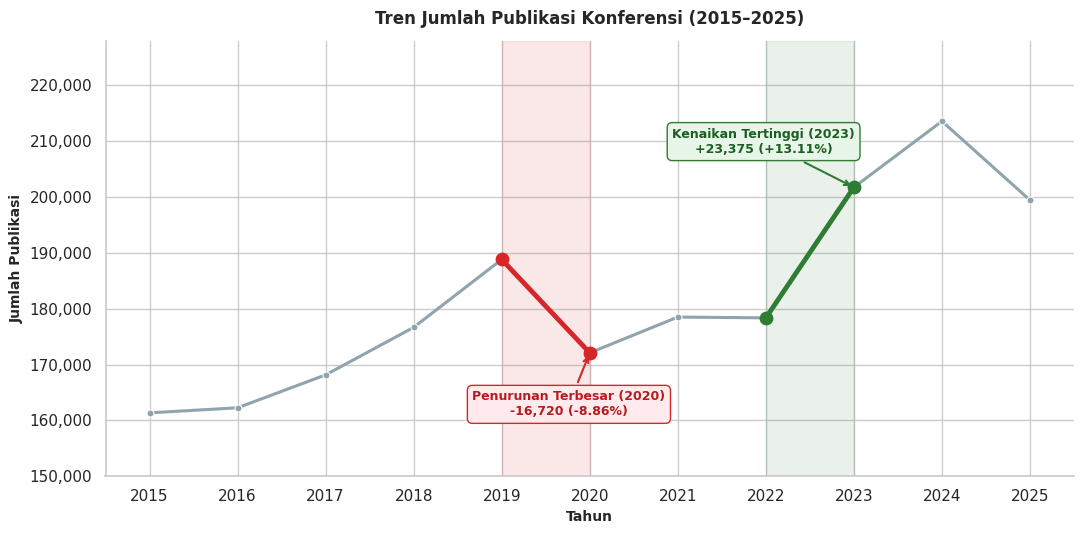

In [53]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(11, 5.5))

# 2. Plot garis utama berwarna netral (abu-abu kebiruan)
sns.lineplot(
    data=df_year,
    x="year",
    y="jumlah",
    color="#90a4ae",
    linewidth=2.2,
    marker="o",
    markersize=5,
    ax=ax
)

# 3. Cari indeks penurunan terbesar & kenaikan tertinggi secara otomatis
idx_drop = df_year["selisih_persen"].idxmin()  # Indeks 5 (2019 -> 2020)
idx_rise = df_year["selisih_persen"].idxmax()  # Indeks 8 (2022 -> 2023)

# ==========================================
# HIGHLIGHT 1: PENURUNAN TERBESAR (MERAH)
# ==========================================
seg_drop = df_year.iloc[idx_drop - 1 : idx_drop + 1]
ax.plot(seg_drop["year"], seg_drop["jumlah"], color="#d62728", linewidth=3.5, zorder=4)
ax.axvspan(seg_drop["year"].iloc[0], seg_drop["year"].iloc[1], color="#d62728", alpha=0.10, zorder=1)
ax.scatter(seg_drop["year"], seg_drop["jumlah"], color="#d62728", s=80, zorder=5)

row_drop = df_year.loc[idx_drop]
ax.annotate(
    f"Penurunan Terbesar (2020)\n{row_drop['selisih']:+,.0f} ({row_drop['selisih_persen']:+.2f}%)",
    xy=(row_drop["year"], row_drop["jumlah"]),
    xytext=(-15, -45),
    textcoords="offset points",
    ha="center",
    fontsize=9,
    fontweight="bold",
    color="#b71c1c",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#ffebee", edgecolor="#d62728", lw=1),
    arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.5)
)

# ==========================================
# HIGHLIGHT 2: KENAIKAN TERTINGGI (HIJAU)
# ==========================================
seg_rise = df_year.iloc[idx_rise - 1 : idx_rise + 1]
ax.plot(seg_rise["year"], seg_rise["jumlah"], color="#2e7d32", linewidth=3.5, zorder=4)
ax.axvspan(seg_rise["year"].iloc[0], seg_rise["year"].iloc[1], color="#2e7d32", alpha=0.10, zorder=1)
ax.scatter(seg_rise["year"], seg_rise["jumlah"], color="#2e7d32", s=80, zorder=5)

row_rise = df_year.loc[idx_rise]
ax.annotate(
    f"Kenaikan Tertinggi (2023)\n{row_rise['selisih']:+,.0f} ({row_rise['selisih_persen']:+.2f}%)",
    xy=(row_rise["year"], row_rise["jumlah"]),
    xytext=(-65, 25),
    textcoords="offset points",
    ha="center",
    fontsize=9,
    fontweight="bold",
    color="#1b5e20",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#e8f5e9", edgecolor="#2e7d32", lw=1),
    arrowprops=dict(arrowstyle="->", color="#2e7d32", lw=1.5)
)

# 4. Rapikan sumbu, label tahun, dan judul
ax.set_xticks(df_year["year"])
ax.set_ylim(150000, 228000)  # Memberi ruang atas & bawah agar kotak anotasi tidak terpotong
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{int(y):,}"))
ax.set_title("Tren Jumlah Publikasi Konferensi (2015–2025)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Tahun", fontsize=10, fontweight="bold")
ax.set_ylabel("Jumlah Publikasi", fontsize=10, fontweight="bold")
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

In [54]:
df_hasil=df_hasil.sort_values(by='jumlah publikasi',ascending=False)

In [55]:
df_hasil

,venue_normalized,jumlah publikasi,jumlah authors
0,neurips,25523,57823
1,cvpr,22776,47638
2,icassp,21606,42036
3,hci,19913,37850
4,igarss,19687,35213
5,aaai,19266,46316
6,emnlp,15528,35553
7,chi,14912,29958
8,embc,14677,39312
9,acl,14633,33514


In [56]:
df2[df2['venue_normalized']=='neurips']['year'].value_counts()

,count
year,
2025,5833
2024,4559
2023,3580
2022,2878
2021,2430
2020,1989
2019,1518
2018,1009
2017,699


In [57]:
df_year

,year,jumlah,jumlah_sebelumnya,selisih,selisih_persen
0,2015,161353,NaN,NaN,NaN
1,2016,162259,161353.0,906.0,0.56
2,2017,168151,162259.0,5892.0,3.63
3,2018,176661,168151.0,8510.0,5.06
4,2019,188817,176661.0,12156.0,6.88
5,2020,172097,188817.0,-16720.0,-8.86
6,2021,178502,172097.0,6405.0,3.72
7,2022,178363,178502.0,-139.0,-0.08
8,2023,201738,178363.0,23375.0,13.11
9,2024,213570,201738.0,11832.0,5.87


In [58]:
# Berdasarkan hasil analisis, jelaskan:
# o Konferensi mana yang paling populer berdasarkan jumlah publikasi?
# neurips memiliki 25523 jumlah publikasi, karena nurips diselenggarakan setiap tahun dari 2015 sampai 2025
# o Apakah konferensi dengan jumlah publikasi terbanyak juga memiliki jumlah author
# unik terbanyak?
# pada ranking 1 sampai 2 menunujukkan pola yang bertalian yaitu jumlah publikasi banyak maka jumlah author juga mengikuti,
# namun jumlah authors terbanyak ketiga justru datang dari confrence yang ranking 6 dari totao jumlah publikasi
# o Bagaimana perubahan aktivitas publikasi konferensi selama periode pengamatan?
# terjadi peningkatan paling tinggi periode 2022 menuju 2023 naik 8% sekitar 23 ribu conference, diakibatkan fonema munculnya trend AI ke masyarakat
# terjadi penurunan tajam dari periode 2019 ke 2020 turun sekitar 9% sektiar 16 ribu conference dari tahun sebelumnya 2019, diakibatkan fenomena global covid

In [62]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2000959 entries, 11 to 2001014
Data columns (total 13 columns):
 #   Column              Dtype 
---  ------              ----- 
 0   key                 object
 1   mdate               object
 2   authors             object
 3   title               object
 4   pages               object
 5   year                int64 
 6   venue               object
 7   doi                 object
 8   crossref            object
 9   url                 object
 10  authors_tuple       object
 11  authors_normalized  object
 12  venue_normalized    object
dtypes: int64(1), object(12)
memory usage: 213.7+ MB


task 3

In [72]:
import ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

base = df2[['authors_normalized', 'venue_normalized', 'year']].copy()

# Jika data dimuat dari CSV, list biasanya terbaca sebagai string
if isinstance(base['authors_normalized'].iloc[0], str):
    base['authors_normalized'] = base['authors_normalized'].apply(ast.literal_eval)

# Buang baris tanpa venue/tahun
base = base.dropna(subset=['venue_normalized', 'year'])
base = base[base['venue_normalized'].str.strip() != '']
base['year'] = base['year'].astype(int)

# Format long: 1 baris = 1 (author, venue, year) dari 1 paper
long_df = (
    base.explode('authors_normalized')
        .rename(columns={'authors_normalized': 'author',
                         'venue_normalized': 'venue'})
        .dropna(subset=['author'])
)
print("Baris long:", len(long_df))

Baris long: 7881218


In [74]:
long_df

,author,venue,year
11,carina corbin,iwsds,2015
11,fabrizio morbini,iwsds,2015
11,david r. traum,iwsds,2015
17,luis fernando d'haro,iwsds,2015
17,seokhwan kim,iwsds,2015
...,...,...,...
2001057,celina m. h. de figueiredo,lagos,2019
2001057,raphael machado,lagos,2019
2001057,uéverton s. souza,lagos,2019
2001014,zhiwei zou,isdt,2017


In [75]:
# author based trx
# drop_duplicates dulu agar item unik per transaksi (transaksi = himpunan, bukan multiset)
a_pairs = long_df[['author', 'venue']].drop_duplicates()

tx_author = (
    a_pairs.groupby('author')['venue']
           .apply(lambda s: sorted(s))
           .rename('items')
           .reset_index()
)
tx_author['n_items'] = tx_author['items'].str.len()

In [76]:
# author-year-based trx
ay_pairs = long_df[['author', 'year', 'venue']].drop_duplicates()

tx_author_year = (
    ay_pairs.groupby(['author', 'year'])['venue']
            .apply(lambda s: sorted(s))
            .rename('items')
            .reset_index()
)
tx_author_year['n_items'] = tx_author_year['items'].str.len()


In [78]:
print("=== Author-Based: 10 acak ===")
display(tx_author.sample(10, random_state=42))

print("=== Author-Based: 10 dengan item >= 3 ===")
display(tx_author[tx_author['n_items'] >= 3].sample(10, random_state=42))

print("=== Author-Year: 10 acak ===")
display(tx_author_year.sample(10, random_state=42))

print("=== Author-Year: 10 dengan item >= 2 ===")
display(tx_author_year[tx_author_year['n_items'] >= 2].sample(10, random_state=42))

=== Author-Based: 10 acak ===


,author,items,n_items
1225536,pierre kleberger,"[dsn, dsn-w, prdc, vnc]",4
671308,javad tayefi,[iwcit],1
754071,joshua c. zhao 0001,"[cvpr, dsn-s, sp]",3
104795,andrew dillon,[asist],1
764477,juan f. valencia,[hci],1
1667031,xin (robert) luo,"[amcis, hicss, icec, pacis]",4
1331485,ruotian lu,[icc],1
1583608,vadim levin,[vlsi technology and circuits],1
1111386,naghmeh bandari,[embc],1
1384689,sebastian stutz,[isgt europe],1


=== Author-Based: 10 dengan item >= 3 ===


,author,items,n_items
744770,joo seong jeong,"[eurosys, hotos, icdcs, mobisys, nsdi, osdi]",6
1385961,sefa kayraklik,"[blackseacom, icc, siu, softcom, vtc2023-sprin...",6
1751442,yuelu wang,"[csai, dsde, icbdt]",3
803629,karim ben alaya,"[icmv, idaacs, iwssip]",3
403742,elie cattan,"[aime, chi, icsm, iss, its]",5
344430,davide fissore,"[i2mtc, ictai, ppdp]",3
959539,marcia pasin,"[ant/edi40, cec, compsac, iccp, iceis, icinco,...",14
1009263,matthew p. bowers,"[arso, biodevices, biostec, icra]",4
401009,elena kuss,"[emisa, er, er forum/demos, iswc, otm conferen...",5
1090268,moritz bärthel,"[acssc, asap, conga, eusipco, ieeeconf, iscas,...",9


=== Author-Year: 10 acak ===


,author,year,items,n_items
1414668,ivan bogatyy,2015,[websci],1
805352,dirk inzé,2021,[rovisp],1
567644,chi-kiu lo,2019,"[conll, wmt]",2
3535486,vijaynagtangirala,2023,[ibica],1
1959596,levent tolga eren,2018,[aist],1
1669269,josef tkadlec,2023,[ecai],1
2455458,mónica de la roca,2023,[fie],1
811548,dmitry petrov,2020,"[icin, icumt, ieee sensors]",3
378075,bart a. j. m. wagemans,2023,[miccai],1
1978705,lijie deng,2017,[miccai],1


=== Author-Year: 10 dengan item >= 2 ===


,author,year,items,n_items
3364504,tatsuya kawahara,2017,"[apsipa, asru, icaart, icassp, ijcnlp, intersp...",10
449848,bowen tian,2016,"[ipccc, nas]",2
970358,faran ahmad,2019,"[ijcai, wacv]",2
1840822,kevin doherty,2021,"[chi, cui]",2
507644,catalin visan,2023,"[islped, sped]",2
2939718,ruikun zhou,2025,"[acc, cdc, l4dc]",3
3291952,sungchul kang,2016,"[icra, iros]",2
313694,arnavi chheda-kothary,2025,"[acl, assets, chi, iui]",4
2367125,mingxuan zhao,2025,"[aaai, iclr]",2
2911831,roman mazurenko,2025,"[itpm, stiot]",2


In [77]:
print("Jumlah transaksi Author-Based     :", len(tx_author))
print("Jumlah transaksi Author-Year-Based:", len(tx_author_year))

Jumlah transaksi Author-Based     : 1819240
Jumlah transaksi Author-Year-Based: 4086070



===== Author-Based =====
Jumlah transaksi      : 1819240
Jumlah item unik      : 4478
Total item (isi tx)   : 4894913
count    1819240.00
mean           2.69
std            4.50
min            1.00
50%            1.00
75%            3.00
90%            6.00
95%            9.00
99%           21.00
max          339.00
Name: n_items, dtype: float64
Transaksi 1 item      : 58.18%
Transaksi >= 2 item   : 41.82%

===== Author-Year-Based =====
Jumlah transaksi      : 4086070
Jumlah item unik      : 4478
Total item (isi tx)   : 6505522
count    4086070.00
mean           1.59
std            1.40
min            1.00
50%            1.00
75%            2.00
90%            3.00
95%            4.00
99%            7.00
max           85.00
Name: n_items, dtype: float64
Transaksi 1 item      : 70.96%
Transaksi >= 2 item   : 29.04%


,Author-Based,Author-Year
n_items,,
1,1058446,2899637
2,291883,662804
3,140870,253969
4,84114,117217
5,55548,60942
6,38645,33996
7,28583,19892
8,21234,12491
9,16392,7621


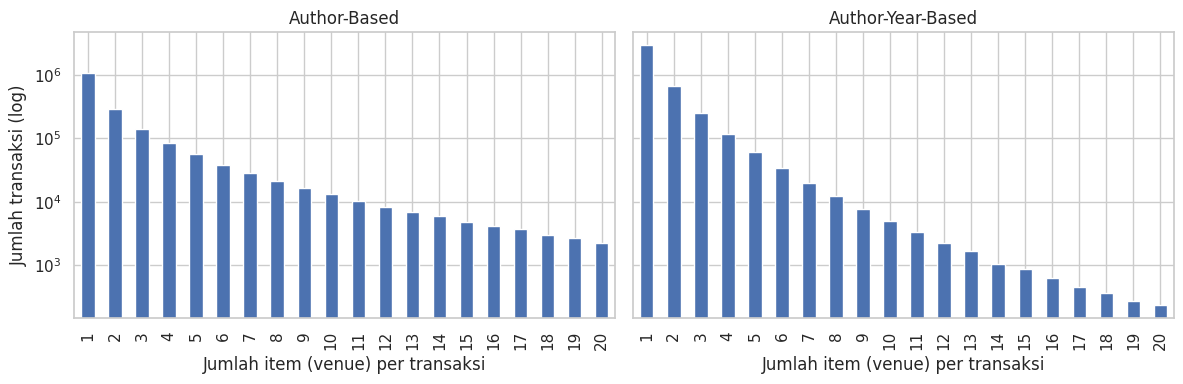

In [79]:
def summarize(tx, name):
    all_items = set(i for items in tx['items'] for i in items)
    n = tx['n_items']
    print(f"\n===== {name} =====")
    print("Jumlah transaksi      :", len(tx))
    print("Jumlah item unik      :", len(all_items))
    print("Total item (isi tx)   :", n.sum())
    print(n.describe(percentiles=[.5, .75, .9, .95, .99]).round(2))
    print("Transaksi 1 item      : %.2f%%" % ((n == 1).mean() * 100))
    print("Transaksi >= 2 item   : %.2f%%" % ((n >= 2).mean() * 100))
    return all_items

items_A  = summarize(tx_author, "Author-Based")
items_AY = summarize(tx_author_year, "Author-Year-Based")

# Distribusi (tabel)
dist_A  = tx_author['n_items'].value_counts().sort_index()
dist_AY = tx_author_year['n_items'].value_counts().sort_index()
display(pd.DataFrame({'Author-Based': dist_A, 'Author-Year': dist_AY}).fillna(0).astype(int).head(15))

# Distribusi (grafik, skala log karena sangat skewed)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, d, t in zip(ax, [dist_A, dist_AY], ['Author-Based', 'Author-Year-Based']):
    d.head(20).plot(kind='bar', ax=a)
    a.set_yscale('log'); a.set_title(t)
    a.set_xlabel('Jumlah item (venue) per transaksi'); a.set_ylabel('Jumlah transaksi (log)')
plt.tight_layout(); plt.show()

In [80]:
# tx_author.to_pickle('tx_author.pkl')
# tx_author_year.to_pickle('tx_author_year.pkl')

In [81]:
# # simpan ke drive
# import shutil

# shutil.copy('/content/tx_author.pkl', '/content/drive/MyDrive/datasets_itb/tx_author.pkl')
# shutil.copy('/content/tx_author_year.pkl', '/content/drive/MyDrive/datasets_itb/tx_author_year.pkl')

'/content/drive/MyDrive/datasets_itb/tx_author_year.pkl'

In [83]:
# Kelebihan dan keterbatasan untuk Frequent Pattern Mining

# Author-Based

# Kelebihan:
# Transaksi lebih padat, sehingga lebih banyak itemset ukuran ≥2 yang muncul dan frequent pattern lebih mudah ditemukan.
# Support stabil dan mudah ditafsirkan sebagai “persentase author yang pernah publikasi di venue X dan Y”.
# Cocok untuk popularitas dan keterkaitan umum antar-konferensi.
# Keterbatasan:
# Tidak ada urutan atau konteks waktu, dan campuran bidang menimbulkan asosiasi semu (spurious).
# Author prolifik menghasilkan transaksi sangat panjang, sehingga jumlah kombinasi itemset meledak (beban komputasi Apriori).
# Bias ke author yang aktif lama, karena lebih lama berkarier berarti lebih banyak venue.

# Author-Year-Based

# Kelebihan:
# Asosiasi lebih bermakna secara topikal karena venue yang berasosiasi dipakai pada periode yang sama.
# Transaksi pendek sehingga komputasi lebih ringan per transaksi.
# Bisa dianalisis per periode (misalnya dibandingkan antar-dekade) untuk melihat tren.
# Keterbatasan:
# Sangat sparse, karena sebagian besar transaksi berisi 1 item dan tidak berkontribusi pada rule (perlu difilter n_items >= 2).
# Satu author yang aktif lama dihitung berkali-kali, sehingga author tersebut memberi bobot lebih besar pada support.
# Support absolut lebih rendah, jadi min_support harus diturunkan, dan itu justru menaikkan jumlah kandidat.
# Asosiasi lintas tahun (author yang pindah venue dari tahun ke tahun) tidak tertangkap.

,author,items,n_items
0,"""johann"" sebastian rudolph","[description logic, theory combination, and al...",1
1,'anau mesui,[ict4d],1
2,'yinka oyerinde,"[conf-irm, ict4d]",2
3,(sophy) shu-jiun chen,[dublin core conference],1
4,2077ai,[neurips],1
...,...,...,...
1819235,þorsteinn daði gunnarsson,"[clarin annual conference, lrec/coling]",2
1819236,þór breki davíðsson,[amcis],1
1819237,þórhildur þorleiksdóttir,"[acm multimedia, ecir]",2
1819238,þórir hrafn harðarson,[nodalida/baltic-hlt],1
